In [ ]:
import pandas as pd
import numpy as np
import os


# 1. Input / output


input_file = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\Final_matrix_With_Protein_sample_info_5000.csv"
output_dir = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis"

os.makedirs(output_dir, exist_ok=True)

filtered_wide_file = os.path.join(
    output_dir,
    "filtered_barcodes_wide.csv"
)

barcode_by_region_file = os.path.join(
    output_dir,
    "barcodes_by_sample_protein_region.csv"
)

summary_file = os.path.join(
    output_dir,
    "barcode_number_by_sample_protein_region.csv"
)


# 2. Read CSV


df = pd.read_csv(input_file)


df.columns = df.columns.str.strip()

print("Columns in input file:")
print(df.columns.tolist())


# 3. Define columns


region_cols = ["Thalamus", "SNr", "Medulla"]
barcode_col = "Barcode"
protein_col = "Protein"
sample_col = "Sample"

required_cols = (
    region_cols
    + [barcode_col, protein_col, sample_col]
)

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )


# 4. Add a unique barcode ID


df = df.reset_index(drop=True)

df.insert(
    0,
    "barcode_id",
    np.arange(1, len(df) + 1)
)


# 5. Make numeric columns numeric


numeric_cols = region_cols + [barcode_col]

df[numeric_cols] = (
    df[numeric_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# 6. Set Barcode <= 2 to zero


count_cols = ["Thalamus", "SNr", "Medulla", "Barcode"]

df[count_cols] = df[count_cols].mask(
    df[count_cols] <= 2,
    0
)

# 7. Calculate maximum projection count


df["max_region_count"] = df[region_cols].max(axis=1)


# 8. Filter barcodes
#
# Conditions:
# 1. Barcode > 50
# 2. Barcode > max(Thalamus, SNr, Medulla)


filtered_df = df[
    (df[barcode_col] > 50)
    &
    (df[barcode_col] > df["max_region_count"])
].copy()

print(
    f"\nTotal original barcodes: {len(df)}"
)

print(
    f"Barcodes passing filtering: {len(filtered_df)}"
)


# 9. Sort wide-format filtered data


filtered_df = filtered_df.sort_values(
    by=[
        sample_col,
        protein_col,
        barcode_col
    ],
    ascending=[
        True,
        True,
        False
    ]
)


# 10. Convert regions to long format


barcode_by_region = filtered_df.melt(
    id_vars=[
        "barcode_id",
        sample_col,
        protein_col,
        barcode_col,
        "max_region_count"
    ],
    value_vars=region_cols,
    var_name="Region",
    value_name="Region_count"
)


# 11. Remove regions with count = 0


barcode_by_region = barcode_by_region[
    barcode_by_region["Region_count"] > 0
].copy()


barcode_by_region = barcode_by_region.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region",
        barcode_col,
        "Region_count"
    ],
    ascending=[
        True,
        True,
        True,
        False,
        False
    ]
)


barcode_by_region = barcode_by_region[
    [
        "barcode_id",
        sample_col,
        protein_col,
        "Region",
        "Region_count",
        barcode_col,
        "max_region_count"
    ]
]


# 12. Count the number of barcodes in each category


barcode_summary = (
    barcode_by_region
    .groupby(
        [
            sample_col,
            protein_col,
            "Region"
        ],
        as_index=False
    )
    .agg(
        number_of_barcodes=("barcode_id", "nunique"),
        total_region_counts=("Region_count", "sum"),
        mean_region_count=("Region_count", "mean"),
        median_region_count=("Region_count", "median"),
        mean_barcode_count=(barcode_col, "mean")
    )
)

barcode_summary = barcode_summary.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region"
    ]
)


# 13. Print example results


print("\nFiltered wide-format data:")
print(filtered_df.head())

print("\nBarcode data separated by region:")
print(barcode_by_region.head())

print("\nBarcode summary:")
print(barcode_summary.head())


# 14. Save CSV files


filtered_df.to_csv(
    filtered_wide_file,
    index=False
)

barcode_by_region.to_csv(
    barcode_by_region_file,
    index=False
)

barcode_summary.to_csv(
    summary_file,
    index=False
)

print("\nSaved files:")

print(
    f"1. Filtered wide data:\n"
    f"   {filtered_wide_file}"
)

print(
    f"2. Barcodes by Sample, Protein and Region:\n"
    f"   {barcode_by_region_file}"
)

print(
    f"3. Barcode number summary:\n"
    f"   {summary_file}"
)

Columns in input file:
['Thalamus', 'SNr', 'Medulla', 'Barcode', 'Protein', 'Sample']

Total original barcodes: 400000
Barcodes passing filtering: 227575

Filtered wide-format data:
     barcode_id  Thalamus  SNr  Medulla  Barcode Protein   Sample  \
142         143         0    0        0    39274   AP2B1  sample1   
145         146         0    0        0    27861   AP2B1  sample1   
28           29         0    0        0    24898   AP2B1  sample1   
177         178         0    0        0    23431   AP2B1  sample1   
97           98         0    0        0    20196   AP2B1  sample1   

     max_region_count  
142                 0  
145                 0  
28                  0  
177                 0  
97                  0  

Barcode data separated by region:
     barcode_id   Sample Protein    Region  Region_count  Barcode  \
18           45  sample1   AP2B1  Thalamus           101    10923   
22          114  sample1   AP2B1  Thalamus             7     8350   
25           84  

Region: Thalamus
Bin width: 50
Maximum Region_count: 4863
Maximum bin edge: 4900
Samples: ['sample1', 'sample10', 'sample11', 'sample12', 'sample13', 'sample2', 'sample3', 'sample4', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9']
AP2B1: n = 12 samples; samples = ['sample1', 'sample10', 'sample11', 'sample12', 'sample13', 'sample2', 'sample3', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9']
AP2M1: n = 13 samples; samples = ['sample1', 'sample10', 'sample11', 'sample12', 'sample13', 'sample2', 'sample3', 'sample4', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9']
CACNG4: n = 12 samples; samples = ['sample1', 'sample10', 'sample11', 'sample13', 'sample2', 'sample3', 'sample4', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9']
CADM1: n = 12 samples; samples = ['sample1', 'sample10', 'sample11', 'sample12', 'sample13', 'sample2', 'sample3', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9']
DNM1: n = 13 samples; samples = ['sample1', 'sample10', 'sample11', 'sa

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


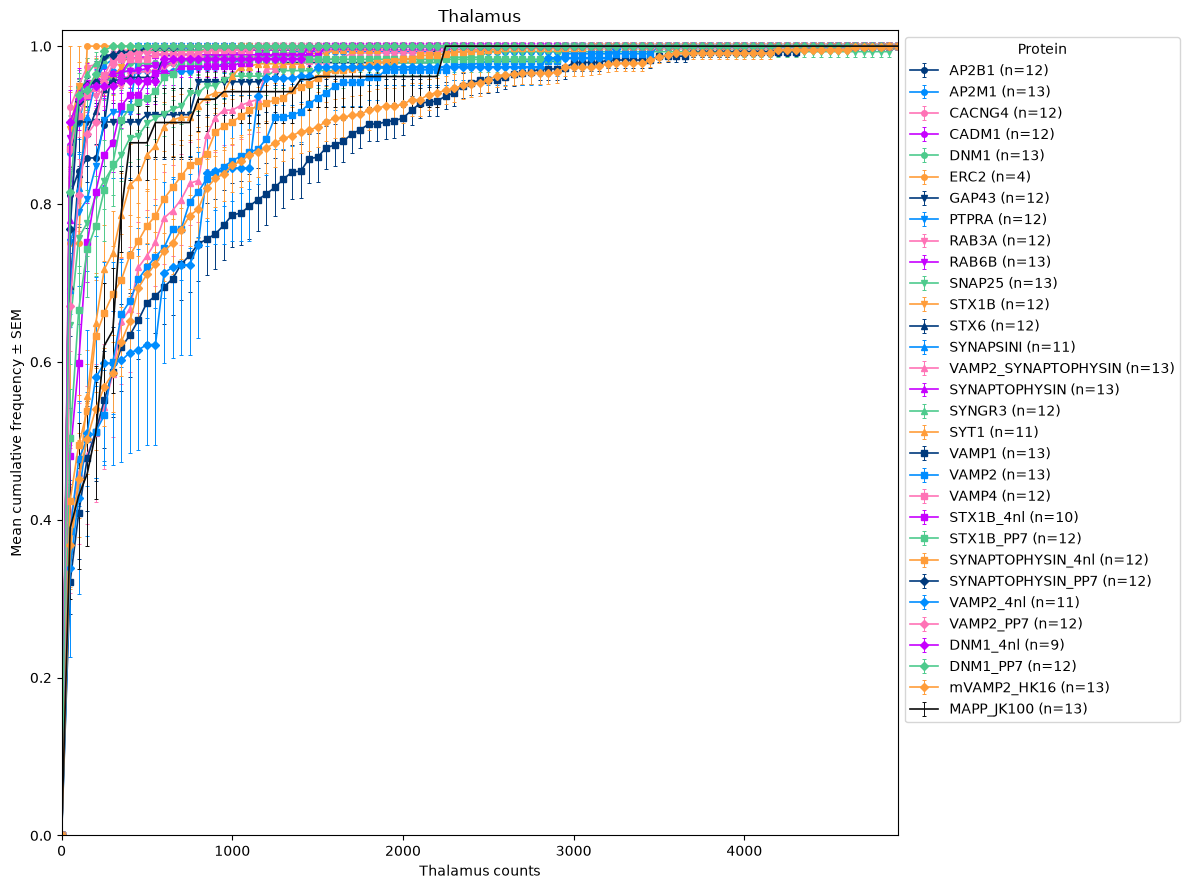

Figure saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis\Thalamus.eps
Summary saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis\Thalamus_summary.csv
Individual curves saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis\Thalamus_individual_sample_curves.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import math


# 1. Input / output


input_file = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis\barcodes_by_sample_protein_region.csv"
output_file = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\06232026_analysis\Thalamus.eps"

region_of_interest = "Thalamus"


bin_width = 50

minimum_samples = 2


errorbar_every = 1


# 2. Protein order


protein_list = [
    "AP2B1",
    "AP2M1",
    "CACNG4",
    "CADM1",
    "DNM1",
    "ERC2",
    "GAP43",
    "PTPRA",
    "RAB3A",
    "RAB6B",
    "SNAP25",
    "STX1B",
    "STX6",
    "SYNAPSINI",
    "VAMP2_SYNAPTOPHYSIN",
    "SYNAPTOPHYSIN",
    "SYNGR3",
    "SYT1",
    "VAMP1",
    "VAMP2",
    "VAMP4",
    "STX1B_4nl",
    "STX1B_PP7",
    "SYNAPTOPHYSIN_4nl",
    "SYNAPTOPHYSIN_PP7",
    "VAMP2_4nl",
    "VAMP2_PP7",
    "DNM1_4nl",
    "DNM1_PP7",
    "mVAMP2_HK16",
    "MAPP_JK100"
]


# 3. Color and marker settings


color = [
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#0d0d0d"
]

marker = [
    "o", "o", "o", "o", "o", "o",
    "v", "v", "v", "v", "v", "v",
    "^", "^", "^", "^", "^", "^",
    "s", "s", "s", "s", "s", "s",
    "D", "D", "D", "D", "D", "D",
    "none"
]

# =====================================================
# 4. Read data
# =====================================================

df = pd.read_csv(input_file)

df.columns = df.columns.str.strip()

required_cols = [
    "Sample",
    "Protein",
    "Region",
    "Region_count"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df["Sample"] = df["Sample"].astype(str).str.strip()
df["Protein"] = df["Protein"].astype(str).str.strip()
df["Region"] = df["Region"].astype(str).str.strip()

df["Region_count"] = pd.to_numeric(
    df["Region_count"],
    errors="coerce"
)

df = df.dropna(
    subset=[
        "Sample",
        "Protein",
        "Region",
        "Region_count"
    ]
).copy()


# 5. Select region data


region_df = df[
    df["Region"].str.lower() == region_of_interest.lower()
].copy()

region_df = region_df[
    region_df["Region_count"] > 0
].copy()

if region_df.empty:
    raise ValueError(
        f"No positive Region_count values found for "
        f"{region_of_interest}."
    )


# 6. Define common bins


maximum_count = region_df["Region_count"].max()

maximum_bin = max(
    3000,
    math.ceil(maximum_count / bin_width) * bin_width
)

bins = np.arange(
    0,
    maximum_bin + bin_width,
    bin_width
)

print(f"Region: {region_of_interest}")
print(f"Bin width: {bin_width}")
print(f"Maximum Region_count: {maximum_count}")
print(f"Maximum bin edge: {maximum_bin}")
print(f"Samples: {sorted(region_df['Sample'].unique())}")


# 7. Function: calculate cumulative curve


def calculate_cumulative_curve(counts, bins):
    """
    Calculate a cumulative probability curve for one
    Sample × Protein combination.

    Returns an array with the same length as bins.
    """

    counts = np.asarray(counts, dtype=float)

    # np.histogram:
    # [0, 50), [50, 100), ...
    bin_counts, _ = np.histogram(
        counts,
        bins=bins
    )

    bin_probability = bin_counts / len(counts)

    cumulative_probability = np.cumsum(
        bin_probability
    )

    # Add cumulative probability = 0 at x = 0
    cumulative_probability = np.insert(
        cumulative_probability,
        0,
        0
    )

    return cumulative_probability


# 8. Calculate per-sample curves and plot mean ± error


plt.figure(figsize=(12, 9))

summary_records = []
curve_records = []

for j, protein in enumerate(protein_list):

    protein_df = region_df[
        region_df["Protein"] == protein
    ].copy()

    if protein_df.empty:
        print(f"No {region_of_interest} data for: {protein}")
        continue

    sample_curves = []
    included_samples = []


    # Calculate one cumulative curve for each sample


    for sample_name, sample_df in protein_df.groupby("Sample"):

        protein_counts = sample_df["Region_count"].to_numpy()

        if len(protein_counts) == 0:
            continue

        cumulative_curve = calculate_cumulative_curve(
            protein_counts,
            bins
        )

        sample_curves.append(cumulative_curve)
        included_samples.append(sample_name)

        # Save individual sample curves
        for x_value, cumulative_value in zip(
            bins,
            cumulative_curve
        ):
            curve_records.append({
                "Protein": protein,
                "Sample": sample_name,
                "RA_count": x_value,
                "Cumulative_probability": cumulative_value,
                "Barcode_number": len(protein_counts)
            })

    n_samples = len(sample_curves)

    if n_samples < minimum_samples:
        print(
            f"Skipping {protein}: only {n_samples} sample(s)"
        )
        continue

    # Shape:
    # n_samples × n_bins
    sample_curves = np.vstack(sample_curves)

    # Mean across samples


    mean_curve = np.mean(
        sample_curves,
        axis=0
    )


    # Error across samples


    if n_samples > 1:

        sd_curve = np.std(
            sample_curves,
            axis=0,
            ddof=1
        )

        sem_curve = sd_curve / np.sqrt(n_samples)

    else:
        sd_curve = np.zeros_like(mean_curve)
        sem_curve = np.zeros_like(mean_curve)

    if error_type.upper() == "SEM":
        error_curve = sem_curve
        error_label = "SEM"

    elif error_type.upper() == "SD":
        error_curve = sd_curve
        error_label = "SD"

    else:
        raise ValueError(
            "error_type must be either 'SEM' or 'SD'."
        )

    print(
        f"{protein}: n = {n_samples} samples; "
        f"samples = {included_samples}"
    )

    # -------------------------------------------------
    # Save summary values
    # -------------------------------------------------

    for i, x_value in enumerate(bins):
        summary_records.append({
            "Protein": protein,
            "RA_count": x_value,
            "Mean_cumulative_probability": mean_curve[i],
            "SD": sd_curve[i],
            "SEM": sem_curve[i],
            "N_samples": n_samples
        })


    # Plot mean line and error bars


    protein_marker = marker[j]


    marker_value = None if protein_marker == "none" else protein_marker

    plt.errorbar(
        bins,
        mean_curve,
        yerr=error_curve,
        color=color[j],
        markeredgecolor=color[j],
        markerfacecolor=color[j],
        marker=marker_value,
        markersize=4,
        linewidth=1.2,
        elinewidth=0.7,
        capsize=1.5,
        capthick=0.7,
        errorevery=errorbar_every,
        label=f"{protein} (n={n_samples})"
    )


# 9. Figure formatting


plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1),
    title="Protein"
)

plt.ylabel(
    f"Mean cumulative frequency ± {error_label}"
)

plt.xlabel(f"{region_of_interest} counts")
plt.title(region_of_interest)

plt.ylim(0, 1.02)
plt.xlim(0, maximum_bin)

plt.tight_layout()


# 10. Save figure and numerical results


output_directory = os.path.dirname(output_file)

if output_directory:
    os.makedirs(
        output_directory,
        exist_ok=True
    )

plt.savefig(
    output_file,
    format="eps",
    bbox_inches="tight"
)

# Save numerical summary
summary_df = pd.DataFrame(summary_records)

summary_output_file = os.path.splitext(
    output_file
)[0] + "_summary.csv"

summary_df.to_csv(
    summary_output_file,
    index=False
)

# Save every individual sample curve
curve_df = pd.DataFrame(curve_records)

curve_output_file = os.path.splitext(
    output_file
)[0] + "_individual_sample_curves.csv"

curve_df.to_csv(
    curve_output_file,
    index=False
)

plt.show()

print(f"Figure saved to: {output_file}")
print(f"Summary saved to: {summary_output_file}")
print(f"Individual curves saved to: {curve_output_file}")